In [1]:
from config_structured_documents_graph import Settings
from dotenv import load_dotenv

load_dotenv()
settings = Settings()

In [2]:
import base64
import fitz
from langchain_openai import ChatOpenAI
from langchain_core.messages import HumanMessage, SystemMessage, AIMessage
from langgraph.graph import END, START, StateGraph, MessagesState
from PIL import Image as PILImage
import io
import pytesseract
import json
from pydantic import BaseModel, Field
from typing import Any

pytesseract.pytesseract.tesseract_cmd = r'C:\Program Files\Tesseract-OCR\tesseract.exe'


vlm = ChatOpenAI(
    model="cyankiwi/Qwen3-VL-8B-Instruct-AWQ-4bit",
    base_url="https://skillet-appealing-broken.ngrok-free.dev/v1",
    api_key="not-needed",
    max_tokens=4900,
)

class MessagesState(MessagesState):
    pages_data : list[dict]
    data_after_check: list[dict]
    rule_groups: list[dict]

class RuleGroup(BaseModel):
    attribute: str = Field(description="Название атрибута, к которому относится группа правил, определённое по смыслу текста")
    rules: list[str] = Field(description="Список правил/требований, относящихся к этому атрибуту")

class GroupingResult(BaseModel):
    groups: list[RuleGroup] = Field(description="Список всех найденных групп правил по атрибутам")

def first_node(state: MessagesState) -> MessagesState:
    _document = fitz.open("API-600.pdf")

    received_text = []
    pages_data = []  # <-- сюда будем собирать данные для JSON

    for page_number in range(7,9):

        first_page = _document[page_number]

        pix = first_page.get_pixmap(dpi=160)

        img = PILImage.open(io.BytesIO(pix.tobytes("png")))

        detected_angle = 0
        confidence = 0.0
        try:
            osd = pytesseract.image_to_osd(img)
            detected_angle = int(
                [line for line in osd.split("\n") if "Rotate" in line][0].split(":")[1].strip()
            )
            confidence = float(
                [line for line in osd.split("\n") if "Orientation confidence" in line][0].split(":")[1].strip()
            )
            print(f"OSD detected rotation: {detected_angle}°, confidence: {confidence}")
        except pytesseract.TesseractError as e:
            print(f"OSD не смог определить ориентацию: {e}")

        if detected_angle != 0 and confidence >= 1.0:
            img_rotated = img.rotate(-detected_angle, expand=True)
            print(f"Изображение повёрнуто на {-detected_angle}°")
        else:
            img_rotated = img
            print("Поворот не применялся (угол 0 или низкая уверенность)")

        # img_rotated.save(f"rotated_page_{page_number}_1.png")

        buf = io.BytesIO()
        img_rotated.save(buf, format="PNG")

        image_bytes = pix.tobytes()
        image_base64 = base64.b64encode(buf.getvalue()).decode("utf-8")

        message = HumanMessage(content=[
            {"type": "image_url", "image_url": {"url": f"data:image/png;base64,{image_base64}"}},
            {"type": "text", "text": "Извлеки текст с этой страницы."}
        ])

        response = vlm.invoke([SystemMessage(content=settings.VL_prompt), message])
        token_usage = response.response_metadata.get("token_usage")
        print(token_usage)

        received_text.append(response)

        # собираем запись для JSON
        pages_data.append({
            "page_number": page_number,
            "source_page_index": page_number,
            "detected_angle": detected_angle,
            "confidence": confidence,
            "content": response.content,
            "token_usage": token_usage,
        })

    # запись в JSON вместо markdown
    # with open("output.json", "w", encoding="utf-8") as f:
    #     json.dump(pages_data, f, ensure_ascii=False, indent=2)

    return {"messages": received_text, "pages_data": pages_data}

def formatting_text_node(state: MessagesState) -> MessagesState:
    llm = ChatOpenAI(model=settings.llmodel, temperature=0, model_kwargs={"response_format": {"type": "json_object"}})

    pages_after_llm = []
    pages = state.get("pages_data")

    if len(pages) == 1:
        # отдельная обработка единственной страницы без пары
        page_copy = dict(pages[0])
        try:
            page_copy["content"] = json.loads(pages[0]["content"])
        except json.JSONDecodeError:
            print("error pass")

        result = llm.invoke([
            SystemMessage(content=settings.llm_prompt),
            HumanMessage(content=json.dumps([page_copy], ensure_ascii=False)),
        ])
        parsed = json.loads(result.content)
        print(f"\n\nsource: {parsed}\n\n")
        result_page = parsed["pages"][0]
        pages_after_llm.append(result_page)
        print(f"\n\n{result.response_metadata.get('token_usage')}\n\npage {result_page}\n\n")

    else:
        for i in range(0, len(pages) - 1):
            page_copy = [dict(pages[i]), dict(pages[i + 1])]
            for index, original in enumerate((pages[i], pages[i + 1])):
                try:
                    page_copy[index]["content"] = json.loads(original["content"])
                except json.JSONDecodeError:
                    print("error pass")

            result = llm.invoke([
                SystemMessage(content=settings.llm_prompt),
                HumanMessage(content=json.dumps(page_copy, ensure_ascii=False)),
            ])
            # ожидаем, что модель вернёт только одну страницу (первую из пары)
            parsed = json.loads(result.content)
            print(f"\n\nsource: {parsed}\n\n")
            result_page = parsed["pages"][0]
            pages_after_llm.append(result_page)
            print(f"\n\n{result.response_metadata.get('token_usage')}\n\npage {result_page}\n\n")

        # последняя страница никогда не была "первой" в паре — обработать отдельно
        last_page = dict(pages[-1])
        try:
            last_page["content"] = json.loads(pages[-1]["content"])
        except json.JSONDecodeError:
            print("error pass")

        result = llm.invoke([
            SystemMessage(content=settings.llm_prompt),
            HumanMessage(content=json.dumps([last_page], ensure_ascii=False)),
        ])
        parsed = json.loads(result.content)
        print(f"\n\nsource: {parsed}\n\n")
        result_page = parsed["pages"][0]
        pages_after_llm.append(result_page)
        print(f"\n\n{result.response_metadata.get('token_usage')}\n\npage {result_page}\n\n")

    # print(f"\n\ndata_after_check {pages_after_llm}\n\n")

    return {
        "messages": [AIMessage(content=json.dumps(pages_after_llm, ensure_ascii=False))],
        "data_after_check": pages_after_llm,
    }

def grouping_rules_node(state: MessagesState) -> MessagesState:
    llm = ChatOpenAI(model=settings.llmodel, temperature=0)
    structured_llm = llm.with_structured_output(GroupingResult, include_raw=True)

    source_data = state.get("data_after_check") or state.get("pages_data")


    def prepare(page):
        page_copy = dict(page)
        content = page.get("content")
        if isinstance(content, str):
            try:
                page_copy["content"] = json.loads(content)
            except json.JSONDecodeError:
                pass
        return page_copy


    all_groups: list[dict] = []
    known_attributes: list[str] = []  # для консистентности названий между вызовами


    def call_llm(pages_chunk):
        nonlocal all_groups, known_attributes

        hint = ""
        if known_attributes:
            hint = (
                "\n\nРанее уже были выделены следующие атрибуты: "
                + ", ".join(known_attributes)
                + ". Если новое правило относится к одному из них — используй ТОЧНО "
                  "такое же название атрибута, не придумывай новую формулировку."
            )

        response = structured_llm.invoke([
            SystemMessage(content=settings.grouping_rules_model_prompt + hint),
            HumanMessage(content=json.dumps(pages_chunk, ensure_ascii=False)),
        ])

        if response["parsing_error"]:
            print("PARSING ERROR:", response["parsing_error"])
            print("RAW:", response["raw"])
            raise response["parsing_error"]

        result = response["parsed"]
        print(f"grouping tokens: {response['raw'].response_metadata.get('token_usage')}")

        for g in result.groups:
            g_dict = g.model_dump()
            all_groups.append(g_dict)
            if g_dict["attribute"] not in known_attributes:
                known_attributes.append(g_dict["attribute"])

    if len(source_data) == 1:
        call_llm([prepare(source_data[0])])
    else:
        for i in range(len(source_data) - 1):
            call_llm([prepare(source_data[i]), prepare(source_data[i + 1])])
        call_llm([prepare(source_data[-1])])

    merged = merge_rule_groups(all_groups)

    return {"rule_groups": merged}


def merge_rule_groups(groups: list[dict]) -> list[dict]:
    """Объединяет группы с одинаковым атрибутом (без учёта регистра/пробелов),
    убирает дублирующиеся формулировки правил внутри группы."""
    merged: dict[str, dict] = {}
    for group in groups:
        key = group["attribute"].strip().lower()
        if key not in merged:
            merged[key] = {"attribute": group["attribute"], "rules": []}
        for rule in group["rules"]:
            if rule not in merged[key]["rules"]:
                merged[key]["rules"].append(rule)
    return list(merged.values())


builder = StateGraph(MessagesState)
builder.add_node(first_node)
builder.add_node(formatting_text_node)
builder.add_node(grouping_rules_node)
builder.add_edge(START, "first_node")
builder.add_edge("first_node", "formatting_text_node")
builder.add_edge("formatting_text_node", "grouping_rules_node")
builder.add_edge("grouping_rules_node", END)
graph = builder.compile()

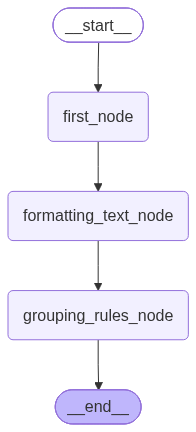

In [3]:
from IPython.display import display, Image

display(Image(graph.get_graph().draw_mermaid_png()))

In [4]:
inv = graph.invoke({"messages": []})

# for message in inv["messages"]:
#     message.pretty_print()

print(inv.get("rule_groups"))

OSD detected rotation: 0°, confidence: 13.91
Поворот не применялся (угол 0 или низкая уверенность)
{'completion_tokens': 963, 'prompt_tokens': 5048, 'total_tokens': 6011, 'completion_tokens_details': None, 'prompt_tokens_details': None}
OSD detected rotation: 0°, confidence: 18.52
Поворот не применялся (угол 0 или низкая уверенность)
{'completion_tokens': 977, 'prompt_tokens': 5048, 'total_tokens': 6025, 'completion_tokens_details': None, 'prompt_tokens_details': None}


source: {'pages': [{'page_number': 7, 'source_page_index': 7, 'detected_angle': 0, 'confidence': 13.91, 'content': '{"blocks": [{"type": "paragraph", "text": "ASME B1.5, Acme Screw Threads"}, {"type": "paragraph", "text": "ASME B1.8, Stub Acme Screw Threads"}, {"type": "paragraph", "text": "ASME B1.12, Class 5 Interference—Fit Thread"}, {"type": "paragraph", "text": "ASME B1.13M, Metric Screw Threads: M Profile"}, {"type": "paragraph", "text": "ASME B16.5, Pipe Flanges and Flanged Fittings NPS 1/2 through NPS 24 Metric

OSD detected rotation: 0°, confidence: 13.74
Поворот не применялся (угол 0 или низкая уверенность)
{'completion_tokens': 3043, 'prompt_tokens': 4696, 'total_tokens': 7739, 'completion_tokens_details': None, 'prompt_tokens_details': None}
================================== Ai Message ==================================

{
  "blocks": [
    {
      "type": "heading",
      "level": 1,
      "text": "Table 1—Minimum Wall Thickness for Body and Bonnet"
    },
    {
      "type": "table",
      "title": "Table 1—Minimum Wall Thickness for Body and Bonnet",
      "columns": [
        "Class Designation",
        "150",
        "300",
        "600",
        "900",
        "1500",
        "2500",
        "Class Designation",
        "Nominal Size DN",
        "Minimum Wall Thickness tm mm (in.)",
        "Nominal Pipe Size NPS"
      ],
      "rows": [
        {
          "Class Designation": "25",
          "150": "6.4 (0.25)",
          "300": "6.4 (0.25)",
          "600": "7.9 (0.31)",
          "900": "12.7 (0.50)",
          "1500": "12.7 (0.50)",
          "2500": "15.0 (0.59)",
          "Class Designation": "1"
        },
        {
          "Class Designation": "32",
          "150": "6.4 (0.25)",
          "300": "6.4 (0.25)",
          "600": "8.6 (0.34)",
          "900": "14.2 (0.56)",
          "1500": "14.2 (0.56)",
          "2500": "17.5 (0.69)",
          "Class Designation": "1¼"
        },
        {
          "Class Designation": "40",
          "150": "6.4 (0.25)",
          "300": "7.9 (0.31)",
          "600": "9.4 (0.37)",
          "900": "15.0 (0.59)",
          "1500": "15.0 (0.59)",
          "2500": "19.1 (0.75)",
          "Class Designation": "1 ½"
        },
        {
          "Class Designation": "50",
          "150": "8.6 (0.34)",
          "300": "9.7 (0.38)",
          "600": "11.2 (0.44)",
          "900": "19.1 (0.75)",
          "1500": "19.1 (0.75)",
          "2500": "22.4 (0.88)",
          "Class Designation": "2"
        },
        {
          "Class Designation": "65",
          "150": "9.7 (0.38)",
          "300": "11.2 (0.44)",
          "600": "11.9 (0.47)",
          "900": "22.4 (0.88)",
          "1500": "22.4 (0.88)",
          "2500": "25.4 (1.00)",
          "Class Designation": "2½"
        },
        {
          "Class Designation": "80",
          "150": "10.4 (0.41)",
          "300": "11.9 (0.47)",
          "600": "12.7 (0.50)",
          "900": "19.1 (0.75)",
          "1500": "23.9 (0.94)",
          "2500": "30.2 (1.19)",
          "Class Designation": "3"
        },
        {
          "Class Designation": "100",
          "150": "11.2 (0.44)",
          "300": "12.7 (0.50)",
          "600": "16.0 (0.63)",
          "900": "21.3 (0.84)",
          "1500": "28.7 (1.13)",
          "2500": "35.8 (1.41)",
          "Class Designation": "4"
        },
        {
          "Class Designation": "150",
          "150": "11.9 (0.47)",
          "300": "16.0 (0.63)",
          "600": "19.1 (0.75)",
          "900": "26.2 (1.03)",
          "1500": "38.1 (1.50)",
          "2500": "48.5 (1.91)",
          "Class Designation": "6"
        },
        {
          "Class Designation": "200",
          "150": "12.7 (0.50)",
          "300": "17.5 (0.69)",
          "600": "25.4 (1.00)",
          "900": "31.8 (1.25)",
          "1500": "47.8 (1.88)",
          "2500": "62.0 (2.44)",
          "Class Designation": "8"
        },
        {
          "Class Designation": "250",
          "150": "14.2 (0.56)",
          "300": "19.1 (0.75)",
          "600": "28.7 (1.13)",
          "900": "36.6 (1.44)",
          "1500": "57.2 (2.25)",
          "2500": "67.6 (2.66)",
          "Class Designation": "10"
        },
        {
          "Class Designation": "300",
          "150": "16.0 (0.63)",
          "300": "20.6 (0.81)",
          "600": "31.8 (1.25)",
          "900": "42.2 (1.66)",
          "1500": "66.8 (2.63)",
          "2500": "86.6 (3.41)",
          "Class Designation": "12"
        },
        {
          "Class Designation": "350",
          "150": "16.8 (0.66)",
          "300": "22.4 (0.88)",
          "600": "35.1 (1.38)",
          "900": "46.0 (1.81)",
          "1500": "69.9 (2.75)",
          "2500": "—",
          "Class Designation": "14"
        },
        {
          "Class Designation": "400",
          "150": "17.5 (0.69)",
          "300": "23.9 (0.94)",
          "600": "38.1 (1.50)",
          "900": "52.3 (2.06)",
          "1500": "79.5 (3.13)",
          "2500": "—",
          "Class Designation": "16"
        },
        {
          "Class Designation": "450",
          "150": "18.3 (0.72)",
          "300": "25.4 (1.00)",
          "600": "41.4 (1.63)",
          "900": "57.2 (2.25)",
          "1500": "88.9 (3.50)",
          "2500": "—",
          "Class Designation": "18"
        },
        {
          "Class Designation": "500",
          "150": "19.1 (0.75)",
          "300": "26.9 (1.06)",
          "600": "44.5 (1.75)",
          "900": "63.5 (2.50)",
          "1500": "98.6 (3.88)",
          "2500": "—",
          "Class Designation": "20"
        },
        {
          "Class Designation": "600",
          "150": "20.6 (0.81)",
          "300": "30.2 (1.19)",
          "600": "50.8 (2.00)",
          "900": "73.2 (2.88)",
          "1500": "114.3 (4.50)",
          "2500": "—",
          "Class Designation": "24"
        },
        {
          "Class Designation": "650",
          "150": "21.4 (0.84)",
          "300": "31.6 (1.24)",
          "600": "—",
          "900": "—",
          "1500": "—",
          "2500": "—",
          "Class Designation": "26"
        },
        {
          "Class Designation": "700",
          "150": "22.2 (0.87)",
          "300": "33.3 (1.31)",
          "600": "—",
          "900": "—",
          "1500": "—",
          "2500": "—",
          "Class Designation": "28"
        },
        {
          "Class Designation": "750",
          "150": "23.0 (0.91)",
          "300": "34.9 (1.37)",
          "600": "—",
          "900": "—",
          "1500": "—",
          "2500": "—",
          "Class Designation": "30"
        },
        {
          "Class Designation": "800",
          "150": "23.8 (0.94)",
          "300": "36.0 (1.41)",
          "600": "—",
          "900": "—",
          "1500": "—",
          "2500": "—",
          "Class Designation": "32"
        },
        {
          "Class Designation": "850",
          "150": "24.6 (0.97)",
          "300": "38.1 (1.50)",
          "600": "—",
          "900": "—",
          "1500": "—",
          "2500": "—",
          "Class Designation": "34"
        },
        {
          "Class Designation": "900",
          "150": "25.3 (1.00)",
          "300": "39.6 (1.56)",
          "600": "—",
          "900": "—",
          "1500": "—",
          "2500": "—",
          "Class Designation": "36"
        },
        {
          "Class Designation": "950",
          "150": "26.1 (1.03)",
          "300": "41.3 (1.63)",
          "600": "—",
          "900": "—",
          "1500": "—",
          "2500": "—",
          "Class Designation": "38"
        },
        {
          "Class Designation": "1000",
          "150": "27.0 (1.06)",
          "300": "43.0 (1.69)",
          "600": "—",
          "900": "—",
          "1500": "—",
          "2500": "—",
          "Class Designation": "40"
        },
        {
          "Class Designation": "1050",
          "150": "27.7 (1.09)",
          "300": "44.4 (1.75)",
          "600": "—",
          "900": "—",
          "1500": "—",
          "2500": "—",
          "Class Designation": "42"
        }
      ]
    }
  ]
}
================================== Ai Message ==================================

[{"page_number": 0, "source_page_index": 0, "detected_angle": 0, "confidence": 13.74, "content": "{\"blocks\": [{\"type\": \"heading\", \"level\": 1, \"text\": \"Table 1—Minimum Wall Thickness for Body and Bonnet\"}, {\"type\": \"table\", \"title\": \"Table 1—Minimum Wall Thickness for Body and Bonnet\", \"columns\": [\"Class Designation/Nominal Size DN\", \"150\", \"300\", \"600\", \"900\", \"1500\", \"2500\", \"Class Designation/Nominal Pipe Size NPS\", \"Minimum Wall Thickness tm mm (in.)\"], \"rows\": [{\"Class Designation/Nominal Size DN\": \"1\", \"150\": \"6.4 (0.25)\", \"300\": \"6.4 (0.25)\", \"600\": \"7.9 (0.31)\", \"900\": \"12.7 (0.50)\", \"1500\": \"12.7 (0.50)\", \"2500\": \"15.0 (0.59)\"}, {\"Class Designation/Nominal Size DN\": \"1¼\", \"150\": \"6.4 (0.25)\", \"300\": \"6.4 (0.25)\", \"600\": \"8.6 (0.34)\", \"900\": \"14.2 (0.56)\", \"1500\": \"14.2 (0.56)\", \"2500\": \"17.5 (0.69)\"}, {\"Class Designation/Nominal Size DN\": \"1 ½\", \"150\": \"6.4 (0.25)\", \"300\": \"7.9 (0.31)\", \"600\": \"9.4 (0.37)\", \"900\": \"15.0 (0.59)\", \"1500\": \"15.0 (0.59)\", \"2500\": \"19.1 (0.75)\"}, {\"Class Designation/Nominal Size DN\": \"2\", \"150\": \"8.6 (0.34)\", \"300\": \"9.7 (0.38)\", \"600\": \"11.2 (0.44)\", \"900\": \"19.1 (0.75)\", \"1500\": \"19.1 (0.75)\", \"2500\": \"22.4 (0.88)\"}, {\"Class Designation/Nominal Size DN\": \"2½\", \"150\": \"9.7 (0.38)\", \"300\": \"11.2 (0.44)\", \"600\": \"11.9 (0.47)\", \"900\": \"22.4 (0.88)\", \"1500\": \"22.4 (0.88)\", \"2500\": \"25.4 (1.00)\"}, {\"Class Designation/Nominal Size DN\": \"3\", \"150\": \"10.4 (0.41)\", \"300\": \"11.9 (0.47)\", \"600\": \"12.7 (0.50)\", \"900\": \"19.1 (0.75)\", \"1500\": \"23.9 (0.94)\", \"2500\": \"30.2 (1.19)\"}, {\"Class Designation/Nominal Size DN\": \"4\", \"150\": \"11.2 (0.44)\", \"300\": \"12.7 (0.50)\", \"600\": \"16.0 (0.63)\", \"900\": \"21.3 (0.84)\", \"1500\": \"28.7 (1.13)\", \"2500\": \"35.8 (1.41)\"}, {\"Class Designation/Nominal Size DN\": \"6\", \"150\": \"11.9 (0.47)\", \"300\": \"16.0 (0.63)\", \"600\": \"19.1 (0.75)\", \"900\": \"26.2 (1.03)\", \"1500\": \"38.1 (1.50)\", \"2500\": \"48.5 (1.91)\"}, {\"Class Designation/Nominal Size DN\": \"8\", \"150\": \"12.7 (0.50)\", \"300\": \"17.5 (0.69)\", \"600\": \"25.4 (1.00)\", \"900\": \"31.8 (1.25)\", \"1500\": \"47.8 (1.88)\", \"2500\": \"62.0 (2.44)\"}, {\"Class Designation/Nominal Size DN\": \"10\", \"150\": \"14.2 (0.56)\", \"300\": \"19.1 (0.75)\", \"600\": \"28.7 (1.13)\", \"900\": \"36.6 (1.44)\", \"1500\": \"57.2 (2.25)\", \"2500\": \"67.6 (2.66)\"}, {\"Class Designation/Nominal Size DN\": \"12\", \"150\": \"16.0 (0.63)\", \"300\": \"20.6 (0.81)\", \"600\": \"31.8 (1.25)\", \"900\": \"42.2 (1.66)\", \"1500\": \"66.8 (2.63)\", \"2500\": \"86.6 (3.41)\"}, {\"Class Designation/Nominal Size DN\": \"14\", \"150\": \"16.8 (0.66)\", \"300\": \"22.4 (0.88)\", \"600\": \"35.1 (1.38)\", \"900\": \"46.0 (1.81)\", \"1500\": \"69.9 (2.75)\", \"2500\": \"—\"}, {\"Class Designation/Nominal Size DN\": \"16\", \"150\": \"17.5 (0.69)\", \"300\": \"23.9 (0.94)\", \"600\": \"38.1 (1.50)\", \"900\": \"52.3 (2.06)\", \"1500\": \"79.5 (3.13)\", \"2500\": \"—\"}, {\"Class Designation/Nominal Size DN\": \"18\", \"150\": \"18.3 (0.72)\", \"300\": \"25.4 (1.00)\", \"600\": \"41.4 (1.63)\", \"900\": \"57.2 (2.25)\", \"1500\": \"88.9 (3.50)\", \"2500\": \"—\"}, {\"Class Designation/Nominal Size DN\": \"20\", \"150\": \"19.1 (0.75)\", \"300\": \"26.9 (1.06)\", \"600\": \"44.5 (1.75)\", \"900\": \"63.5 (2.50)\", \"1500\": \"98.6 (3.88)\", \"2500\": \"—\"}, {\"Class Designation/Nominal Size DN\": \"24\", \"150\": \"20.6 (0.81)\", \"300\": \"30.2 (1.19)\", \"600\": \"50.8 (2.00)\", \"900\": \"73.2 (2.88)\", \"1500\": \"114.3 (4.50)\", \"2500\": \"—\"}, {\"Class Designation/Nominal Size DN\": \"26\", \"150\": \"21.4 (0.84)\", \"300\": \"31.6 (1.24)\", \"600\": \"—\", \"900\": \"—\", \"1500\": \"—\", \"2500\": \"—\"}, {\"Class Designation/Nominal Size DN\": \"28\", \"150\": \"22.2 (0.87)\", \"300\": \"33.3 (1.31)\", \"600\": \"—\", \"900\": \"—\", \"1500\": \"—\", \"2500\": \"—\"}, {\"Class Designation/Nominal Size DN\": \"30\", \"150\": \"23.0 (0.91)\", \"300\": \"34.9 (1.37)\", \"600\": \"—\", \"900\": \"—\", \"1500\": \"—\", \"2500\": \"—\"}, {\"Class Designation/Nominal Size DN\": \"32\", \"150\": \"23.8 (0.94)\", \"300\": \"36.0 (1.41)\", \"600\": \"—\", \"900\": \"—\", \"1500\": \"—\", \"2500\": \"—\"}, {\"Class Designation/Nominal Size DN\": \"34\", \"150\": \"24.6 (0.97)\", \"300\": \"38.1 (1.50)\", \"600\": \"—\", \"900\": \"—\", \"1500\": \"—\", \"2500\": \"—\"}, {\"Class Designation/Nominal Size DN\": \"36\", \"150\": \"25.3 (1.00)\", \"300\": \"39.6 (1.56)\", \"600\": \"—\", \"900\": \"—\", \"1500\": \"—\", \"2500\": \"—\"}, {\"Class Designation/Nominal Size DN\": \"38\", \"150\": \"26.1 (1.03)\", \"300\": \"41.3 (1.63)\", \"600\": \"—\", \"900\": \"—\", \"1500\": \"—\", \"2500\": \"—\"}, {\"Class Designation/Nominal Size DN\": \"40\", \"150\": \"27.0 (1.06)\", \"300\": \"43.0 (1.69)\", \"600\": \"—\", \"900\": \"—\", \"1500\": \"—\", \"2500\": \"—\"}, {\"Class Designation/Nominal Size DN\": \"42\", \"150\": \"27.7 (1.09)\", \"300\": \"44.4 (1.75)\", \"600\": \"—\", \"900\": \"—\", \"1500\": \"—\", \"2500\": \"—\"}]}]}", "token_usage": {"completion_tokens": 3043, "prompt_tokens": 4696, "total_tokens": 7739, "completion_tokens_details": null, "prompt_tokens_details": null}}]
[{'attribute': 'Minimum Wall Thickness', 'rules': ['For Class 150, DN 1, minimum wall thickness is 6.4 mm (0.25 in.)', 'For Class 300, DN 1, minimum wall thickness is 6.4 mm (0.25 in.)', 'For Class 600, DN 1, minimum wall thickness is 7.9 mm (0.31 in.)', 'For Class 900, DN 1, minimum wall thickness is 12.7 mm (0.50 in.)', 'For Class 1500, DN 1, minimum wall thickness is 12.7 mm (0.50 in.)', 'For Class 2500, DN 1, minimum wall thickness is 15.0 mm (0.59 in.)', 'For Class 150, DN 1¼, minimum wall thickness is 6.4 mm (0.25 in.)', 'For Class 300, DN 1¼, minimum wall thickness is 6.4 mm (0.25 in.)', 'For Class 600, DN 1¼, minimum wall thickness is 8.6 mm (0.34 in.)', 'For Class 900, DN 1¼, minimum wall thickness is 14.2 mm (0.56 in.)', 'For Class 1500, DN 1¼, minimum wall thickness is 14.2 mm (0.56 in.)', 'For Class 2500, DN 1¼, minimum wall thickness is 17.5 mm (0.69 in.)', 'For Class 150, DN 1½, minimum wall thickness is 6.4 mm (0.25 in.)', 'For Class 300, DN 1½, minimum wall thickness is 7.9 mm (0.31 in.)', 'For Class 600, DN 1½, minimum wall thickness is 9.4 mm (0.37 in.)', 'For Class 900, DN 1½, minimum wall thickness is 15.0 mm (0.59 in.)', 'For Class 1500, DN 1½, minimum wall thickness is 15.0 mm (0.59 in.)', 'For Class 2500, DN 1½, minimum wall thickness is 19.1 mm (0.75 in.)', 'For Class 150, DN 2, minimum wall thickness is 8.6 mm (0.34 in.)', 'For Class 300, DN 2, minimum wall thickness is 9.7 mm (0.38 in.)', 'For Class 600, DN 2, minimum wall thickness is 11.2 mm (0.44 in.)', 'For Class 900, DN 2, minimum wall thickness is 19.1 mm (0.75 in.)', 'For Class 1500, DN 2, minimum wall thickness is 19.1 mm (0.75 in.)', 'For Class 2500, DN 2, minimum wall thickness is 22.4 mm (0.88 in.)', 'For Class 150, DN 2½, minimum wall thickness is 9.7 mm (0.38 in.)', 'For Class 300, DN 2½, minimum wall thickness is 11.2 mm (0.44 in.)', 'For Class 600, DN 2½, minimum wall thickness is 11.9 mm (0.47 in.)', 'For Class 900, DN 2½, minimum wall thickness is 22.4 mm (0.88 in.)', 'For Class 1500, DN 2½, minimum wall thickness is 22.4 mm (0.88 in.)', 'For Class 2500, DN 2½, minimum wall thickness is 25.4 mm (1.00 in.)', 'For Class 150, DN 3, minimum wall thickness is 10.4 mm (0.41 in.)', 'For Class 300, DN 3, minimum wall thickness is 11.9 mm (0.47 in.)', 'For Class 600, DN 3, minimum wall thickness is 12.7 mm (0.50 in.)', 'For Class 900, DN 3, minimum wall thickness is 19.1 mm (0.75 in.)', 'For Class 1500, DN 3, minimum wall thickness is 23.9 mm (0.94 in.)', 'For Class 2500, DN 3, minimum wall thickness is 30.2 mm (1.19 in.)', 'For Class 150, DN 4, minimum wall thickness is 11.2 mm (0.44 in.)', 'For Class 300, DN 4, minimum wall thickness is 12.7 mm (0.50 in.)', 'For Class 600, DN 4, minimum wall thickness is 16.0 mm (0.63 in.)', 'For Class 900, DN 4, minimum wall thickness is 21.3 mm (0.84 in.)', 'For Class 1500, DN 4, minimum wall thickness is 28.7 mm (1.13 in.)', 'For Class 2500, DN 4, minimum wall thickness is 35.8 mm (1.41 in.)', 'For Class 150, DN 6, minimum wall thickness is 11.9 mm (0.47 in.)', 'For Class 300, DN 6, minimum wall thickness is 16.0 mm (0.63 in.)', 'For Class 600, DN 6, minimum wall thickness is 19.1 mm (0.75 in.)', 'For Class 900, DN 6, minimum wall thickness is 26.2 mm (1.03 in.)', 'For Class 1500, DN 6, minimum wall thickness is 38.1 mm (1.50 in.)', 'For Class 2500, DN 6, minimum wall thickness is 48.5 mm (1.91 in.)', 'For Class 150, DN 8, minimum wall thickness is 12.7 mm (0.50 in.)', 'For Class 300, DN 8, minimum wall thickness is 17.5 mm (0.69 in.)', 'For Class 600, DN 8, minimum wall thickness is 25.4 mm (1.00 in.)', 'For Class 900, DN 8, minimum wall thickness is 31.8 mm (1.25 in.)', 'For Class 1500, DN 8, minimum wall thickness is 47.8 mm (1.88 in.)', 'For Class 2500, DN 8, minimum wall thickness is 62.0 mm (2.44 in.)', 'For Class 150, DN 10, minimum wall thickness is 14.2 mm (0.56 in.)', 'For Class 300, DN 10, minimum wall thickness is 19.1 mm (0.75 in.)', 'For Class 600, DN 10, minimum wall thickness is 28.7 mm (1.13 in.)', 'For Class 900, DN 10, minimum wall thickness is 36.6 mm (1.44 in.)', 'For Class 1500, DN 10, minimum wall thickness is 57.2 mm (2.25 in.)', 'For Class 2500, DN 10, minimum wall thickness is 67.6 mm (2.66 in.)', 'For Class 150, DN 12, minimum wall thickness is 16.0 mm (0.63 in.)', 'For Class 300, DN 12, minimum wall thickness is 20.6 mm (0.81 in.)', 'For Class 600, DN 12, minimum wall thickness is 31.8 mm (1.25 in.)', 'For Class 900, DN 12, minimum wall thickness is 42.2 mm (1.66 in.)', 'For Class 1500, DN 12, minimum wall thickness is 66.8 mm (2.63 in.)', 'For Class 2500, DN 12, minimum wall thickness is 86.6 mm (3.41 in.)', 'For Class 150, DN 14, minimum wall thickness is 16.8 mm (0.66 in.)', 'For Class 300, DN 14, minimum wall thickness is 22.4 mm (0.88 in.)', 'For Class 600, DN 14, minimum wall thickness is 35.1 mm (1.38 in.)', 'For Class 900, DN 14, minimum wall thickness is 46.0 mm (1.81 in.)', 'For Class 1500, DN 14, minimum wall thickness is 69.9 mm (2.75 in.)', 'For Class 150, DN 16, minimum wall thickness is 17.5 mm (0.69 in.)', 'For Class 300, DN 16, minimum wall thickness is 23.9 mm (0.94 in.)', 'For Class 600, DN 16, minimum wall thickness is 38.1 mm (1.50 in.)', 'For Class 900, DN 16, minimum wall thickness is 52.3 mm (2.06 in.)', 'For Class 1500, DN 16, minimum wall thickness is 79.5 mm (3.13 in.)', 'For Class 150, DN 18, minimum wall thickness is 18.3 mm (0.72 in.)', 'For Class 300, DN 18, minimum wall thickness is 25.4 mm (1.00 in.)', 'For Class 600, DN 18, minimum wall thickness is 41.4 mm (1.63 in.)', 'For Class 900, DN 18, minimum wall thickness is 57.2 mm (2.25 in.)', 'For Class 1500, DN 18, minimum wall thickness is 88.9 mm (3.50 in.)', 'For Class 150, DN 20, minimum wall thickness is 19.1 mm (0.75 in.)', 'For Class 300, DN 20, minimum wall thickness is 26.9 mm (1.06 in.)', 'For Class 600, DN 20, minimum wall thickness is 44.5 mm (1.75 in.)', 'For Class 900, DN 20, minimum wall thickness is 63.5 mm (2.50 in.)', 'For Class 1500, DN 20, minimum wall thickness is 98.6 mm (3.88 in.)', 'For Class 150, DN 24, minimum wall thickness is 20.6 mm (0.81 in.)', 'For Class 300, DN 24, minimum wall thickness is 30.2 mm (1.19 in.)', 'For Class 600, DN 24, minimum wall thickness is 50.8 mm (2.00 in.)', 'For Class 900, DN 24, minimum wall thickness is 73.2 mm (2.88 in.)', 'For Class 1500, DN 24, minimum wall thickness is 114.3 mm (4.50 in.)', 'For Class 150, DN 26, minimum wall thickness is 21.4 mm (0.84 in.)', 'For Class 300, DN 26, minimum wall thickness is 31.6 mm (1.24 in.)', 'For Class 150, DN 28, minimum wall thickness is 22.2 mm (0.87 in.)', 'For Class 300, DN 28, minimum wall thickness is 33.3 mm (1.31 in.)', 'For Class 150, DN 30, minimum wall thickness is 23.0 mm (0.91 in.)', 'For Class 300, DN 30, minimum wall thickness is 34.9 mm (1.37 in.)', 'For Class 150, DN 32, minimum wall thickness is 23.8 mm (0.94 in.)', 'For Class 300, DN 32, minimum wall thickness is 36.0 mm (1.41 in.)', 'For Class 150, DN 34, minimum wall thickness is 24.6 mm (0.97 in.)', 'For Class 300, DN 34, minimum wall thickness is 38.1 mm (1.50 in.)', 'For Class 150, DN 36, minimum wall thickness is 25.3 mm (1.00 in.)', 'For Class 300, DN 36, minimum wall thickness is 39.6 mm (1.56 in.)', 'For Class 150, DN 38, minimum wall thickness is 26.1 mm (1.03 in.)', 'For Class 300, DN 38, minimum wall thickness is 41.3 mm (1.63 in.)', 'For Class 150, DN 40, minimum wall thickness is 27.0 mm (1.06 in.)', 'For Class 300, DN 40, minimum wall thickness is 43.0 mm (1.69 in.)', 'For Class 150, DN 42, minimum wall thickness is 27.7 mm (1.09 in.)', 'For Class 300, DN 42, minimum wall thickness is 44.4 mm (1.75 in.)']}]